# Poisson statistics for dust-clump detection
### Tutorial 2a · Statistical learning for planet formation

**Question:** How can we tell a concentration of solid particles from a chance
fluctuation in a disk patch?

**Approach:** Start with a spatial null model, understand its counts, inject two
concentrations, and measure their disagreement with the null.

**Data:** Reproducible synthetic coordinates of equal-weight tracers. Everything
needed is generated here; there are no downloads or private datasets.

This independently written adaptation follows the teaching sequence of
Yuan-Sen Ting (2026), *Statistical Machine Learning for Astronomy*, Tutorial 2a,
printed pp. 563–591. The astronomical setting changes from stellar clusters to
dust concentrations. The section order and statistical objectives are retained.
Scientific references and a correspondence table appear at the end and in the
accompanying README.

## Introduction: from a random dust field to a candidate concentration

The formation of planetesimals requires solids to concentrate. Aerodynamic
feedback between gas and dust can drive the streaming instability
([Youdin & Goodman 2005](https://arxiv.org/abs/astro-ph/0409263)).
Nonlinear simulations show strong particle concentrations in some regimes
([Johansen & Youdin 2007](https://arxiv.org/abs/astro-ph/0702626)).
These results motivate a statistical question: **is a measured local count
consistent with randomly placed tracers?**

We study a square, two-dimensional patch. A dot is an equal-weight numerical
tracer, not an individually observed grain. The coordinate unit is a chosen gas
pressure scale height, $H$. Thus $x/H$ and $y/H$ are dimensionless, and the
background intensity $\rho$ has units of tracers per $H^2$.

A homogeneous Poisson point process describes our random background. A
concentration departs from that background by increasing the local count.
We begin with a known null model so that we can check every step.

The two injected Gaussian clumps are teaching models: their sizes, locations,
and populations are chosen here, not taken from the cited simulations. No
gas dynamics, dust drag, gravity, or collisions are evolved. Detecting a
concentration will not, by itself, identify its formation mechanism or prove
that it can collapse into a planetesimal.

## Prerequisites and learning objectives

You need basic Python, NumPy arrays, plotting, and the ideas of a probability
distribution, expectation, and independence.

By the end you should be able to:

1. Connect the intensity of a spatial Poisson process to counts in an aperture.
2. Explain the area dependence of counts in neighboring annuli.
3. Construct marginal, joint, and conditional count distributions.
4. Detect departures from a uniform background using Poisson likelihoods.
5. Distinguish an exact-count probability from an upper-tail probability.
6. Estimate a Poisson rate by maximum likelihood.
7. Recognize boundary effects, overlapping measurements, and assumptions that
   limit an interpretation in terms of disk physics.

**How to work:** Read the prediction questions before running the following cell.
All cells are complete; the exercises at the end are optional extensions.

## Setup

Run from the first cell in a Python environment with the repository dependencies.
The random streams for the background, annular experiments, clumps, and control
field are separate. Running all cells from a fresh kernel reproduces the saved
CSV data and figures.

Every figure is also saved in the neighboring figures folder. The data and
provenance are exported near the end. No file outside this tutorial is changed.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform

import numpy as np
import matplotlib.pyplot as plt
import matplotidlib
from matplotlib.patches import Circle, Wedge
from scipy.spatial import cKDTree
from scipy.special import gammaln, xlogy
from scipy.stats import poisson, gaussian_kde
from IPython.display import Markdown, display

# Use the project's requested IDL-inspired theme without replacing its typography,
# tick directions, axes, line styling, or categorical color cycle.
STYLE_FONT = matplotidlib.use()
plt.rcParams["figure.dpi"] = 110  # Notebook display resolution; exports use the theme's 300 dpi.

cwd = Path.cwd()
TUTORIAL_DIR = (
    cwd if (cwd / "poisson_dust_clumps.ipynb").exists()
    else cwd / "tutorials" / "02a_poisson_dust_clumps"
)
if not TUTORIAL_DIR.is_dir():
    raise FileNotFoundError("Start Jupyter from the repository or tutorial directory.")
FIGURES = TUTORIAL_DIR / "figures"
DATA = TUTORIAL_DIR / "data"
FIGURES.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

SEED = 42
seeds = {"background": SEED, "annuli": SEED + 1,
         "clumps": SEED + 2, "control": SEED + 3}
L = 1.0                  # Side length in units of H
RHO = 10_000.0           # Numerical tracers per H^2; not a physical dust density
RADII = np.array([0.0, 0.02, 0.04])  # Distances in H
AREAS = np.pi * np.diff(RADII**2)
LAMBDA = RHO * AREAS

def finish(fig, name):
    '''Save a readable, reproducible figure, display it, then release its memory.'''
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)

def patch_axes(ax):
    ax.set(xlabel=r"$x/H$ (radial)", ylabel=r"$y/H$ (azimuthal)",
           xlim=(0, L), ylim=(0, L))
    ax.set_aspect("equal")

print(f"Expected patch population: {RHO * L**2:,.0f} tracers")
print(f"Annular expectations: {LAMBDA.round(3)}")
print(f"Plot style: matplotidlib; selected font: {STYLE_FONT}")

Expected patch population: 10,000 tracers
Annular expectations: [12.566 37.699]
Plot style: matplotidlib; selected font: AVHershey Simplex


## 1. Modeling the uniform background

Our null model has a constant intensity $\rho$, independent placements, and no
preferred position within the patch. For any region of area $A$,

$$N_A\sim\operatorname{Poisson}(\lambda),\qquad \lambda=\rho A,$$
$$P(N_A=k\mid\lambda)=\frac{\lambda^k e^{-\lambda}}{k!},
\qquad k=0,1,2,\ldots.$$

To generate a Poisson process in a finite square, first draw
$N_{\rm box}\sim\operatorname{Poisson}(\rho L^2)$, then place that many points
uniformly. The realized total is not required to equal its expectation.

**A useful distinction:** fixing the total to exactly 10,000 and then drawing
uniform coordinates would make region counts binomial conditional on that total.
At small area fractions it approximates a Poisson process, but here we use the
Poisson construction directly.

**Predict:** Will every small region contain exactly $\rho A$ particles?

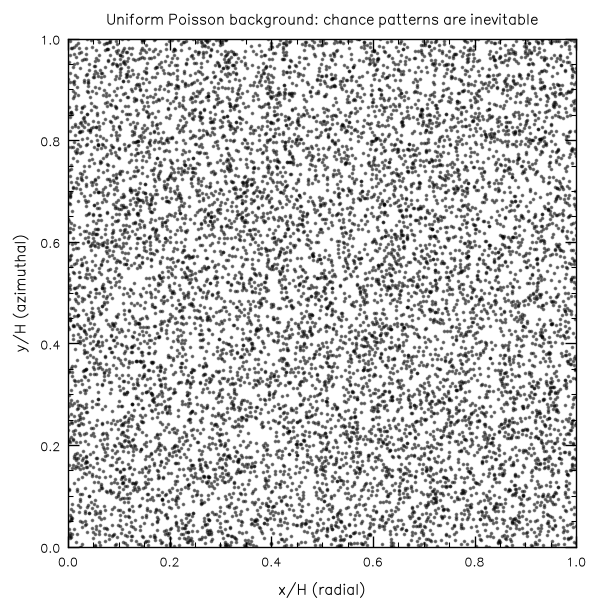

Realized background population: 10,085
Realized density: 10,085 tracers per H^2


In [2]:
def generate_poisson_patch(rho, side, rng):
    '''Homogeneous spatial Poisson process on [0, side)^2.'''
    n = rng.poisson(rho * side**2)
    return rng.uniform(0.0, side, size=(n, 2))

background = generate_poisson_patch(RHO, L, np.random.default_rng(seeds["background"]))

fig, ax = plt.subplots(figsize=(6.7, 6))
ax.scatter(background[:, 0], background[:, 1], s=2, alpha=0.45, rasterized=True)
patch_axes(ax)
ax.set_title("Uniform Poisson background: chance patterns are inevitable")
finish(fig, "01_uniform_background")
print(f"Realized background population: {len(background):,}")
print(f"Realized density: {len(background) / L**2:,.0f} tracers per H^2")

### Expected density is fixed; the measured count is random

$\rho$ is a parameter of the generating model. $N_A$ is a random variable that
changes from one realization to another. The realized density of the whole box
also fluctuates around $\rho$.

A patch that looks uneven is therefore not automatically evidence for physical
clustering. We need the distribution of fluctuations predicted by the null.

## 2. Random variables and annular counting statistics

Take two disjoint regions about the same center: an inner disk from 0 to
$0.02H$ and an outer annulus from $0.02H$ to $0.04H$. Their areas are

$$A_j=\pi(r_{j+1}^2-r_j^2),\qquad \lambda_j=\rho A_j.$$

**Predict:** The outer radius doubles, but does the second region have twice,
three times, or four times the area of the first?

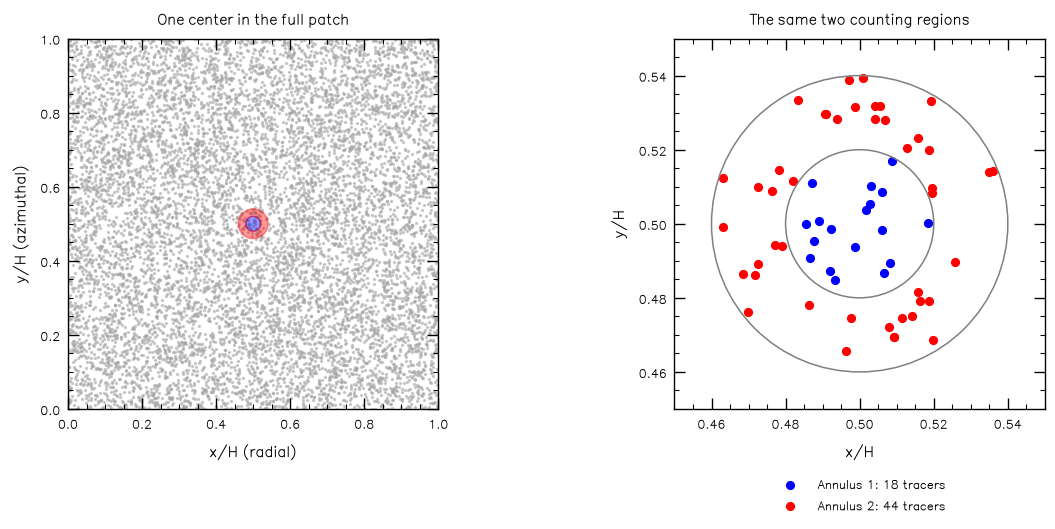

Area ratio A2/A1 = 3
Expected counts: inner = 12.57, outer = 37.70


In [3]:
center = np.array([0.5, 0.5])
distances = np.linalg.norm(background - center, axis=1)
annulus_id = np.searchsorted(RADII, distances, side="right") - 1

fig, axes = plt.subplots(1, 2, figsize=(11, 4.7), layout="constrained")
axes[0].scatter(background[:, 0], background[:, 1], s=1.5, color="0.65", alpha=0.5)
patch_axes(axes[0])
for j, color in enumerate(["C1", "C2"]):
    ring = Wedge(center, RADII[j + 1], 0, 360,
                 width=RADII[j + 1] - RADII[j],
                 facecolor=color, alpha=0.4, edgecolor=color)
    axes[0].add_patch(ring)
    selected = background[annulus_id == j]
    axes[1].scatter(selected[:, 0], selected[:, 1], s=25, color=color,
                    label=f"Annulus {j + 1}: {len(selected)} tracers")
for r in RADII[1:]:
    axes[1].add_patch(Circle(center, r, fill=False, color="0.5", lw=1))
axes[0].set_title("One center in the full patch")
axes[1].set(xlabel=r"$x/H$", ylabel=r"$y/H$",
            xlim=(0.45, 0.55), ylim=(0.45, 0.55), title="The same two counting regions")
axes[1].set_aspect("equal")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15))
finish(fig, "02_annular_geometry")
print(f"Area ratio A2/A1 = {AREAS[1] / AREAS[0]:.0f}")
print(f"Expected counts: inner = {LAMBDA[0]:.2f}, outer = {LAMBDA[1]:.2f}")

The ratio is **three**, because the outer annulus excludes the inner disk.
Its larger mean count is explained by geometry, even though the density is the
same in both regions.

One center supplies only one pair of counts. As in the textbook, we next count
neighbors around every tracer. We exclude the central tracer itself. These
apertures overlap, so the resulting rows are useful spatial measurements but
are **not independent repeated experiments**.

### Boundary geometry: a periodic square

A circle centered near an edge extends beyond the square. Counting only visible
points would underestimate the density there. We first use periodic geometry:
opposite edges connect, and the shortest coordinate separation is

$$\Delta x_{\rm per}=
\left[(x-x_c+L/2)\bmod L\right]-L/2,$$

with the same rule for $\Delta y$.

This is a convenient geometric null model. It is not a hydrodynamic shearing
box. Use radii smaller than $L/2$, for which our circular area formula applies.
The explicit calculation below shows one aperture; a spatial tree then repeats
the same count efficiently without allocating an all-pairs distance matrix.

In [4]:
delta = (background - background[0] + L / 2) % L - L / 2
periodic_distances = np.linalg.norm(delta, axis=1)
periodic_distances[0] = np.inf  # A particle is not its own neighbor.
first_counts = np.array([
    np.count_nonzero((periodic_distances >= lo) & (periodic_distances < hi))
    for lo, hi in zip(RADII[:-1], RADII[1:])
])

def neighbor_counts(points, edges, side, periodic=True):
    '''Counts about each particle in half-open annuli [r_inner, r_outer).'''
    edges = np.asarray(edges, dtype=float)
    if edges[0] != 0 or np.any(np.diff(edges) <= 0) or edges[-1] >= side / 2:
        raise ValueError("Use increasing edges starting at zero and ending below L/2.")
    tree = cKDTree(points, boxsize=side if periodic else None)
    # query_ball_point includes its outer boundary; nextafter makes it half-open.
    cumulative = np.column_stack([
        tree.query_ball_point(points, np.nextafter(r, 0), return_length=True) - 1
        for r in edges[1:]
    ])
    return np.diff(np.column_stack([np.zeros(len(points), dtype=int), cumulative]), axis=1)

def aperture_counts(points, centers, radius, side, periodic=True):
    '''Counts at fixed positions, including all particles inside each aperture.'''
    if not 0 < radius < side / 2:
        raise ValueError("The aperture radius must be between zero and L/2.")
    tree = cKDTree(points, boxsize=side if periodic else None)
    return tree.query_ball_point(
        np.asarray(centers), np.nextafter(radius, 0), return_length=True
    )

background_counts = neighbor_counts(background, RADII, L)
assert np.array_equal(first_counts, background_counts[0])
print("Explicit periodic count:", first_counts)
print("Spatial-tree count:     ", background_counts[0])

Explicit periodic count: [ 8 36]
Spatial-tree count:      [ 8 36]


### Compare the measurements with the Poisson distribution

For a Poisson variable, the mean and variance both equal $\lambda$.
We compute the exact-count probability in log space:

$$\log P(k\mid\lambda)=k\log\lambda-\lambda-\log(k!).$$

The logarithm avoids numerical underflow. The code uses $\log(k!)=
\log\Gamma(k+1)$ and a numerically defined $0\log 0=0$ so that the case
$\lambda=0$ is handled correctly too.

Annulus 1: expected mean 12.566; measured mean 12.786; variance 13.270
Annulus 2: expected mean 37.699; measured mean 37.976; variance 37.474


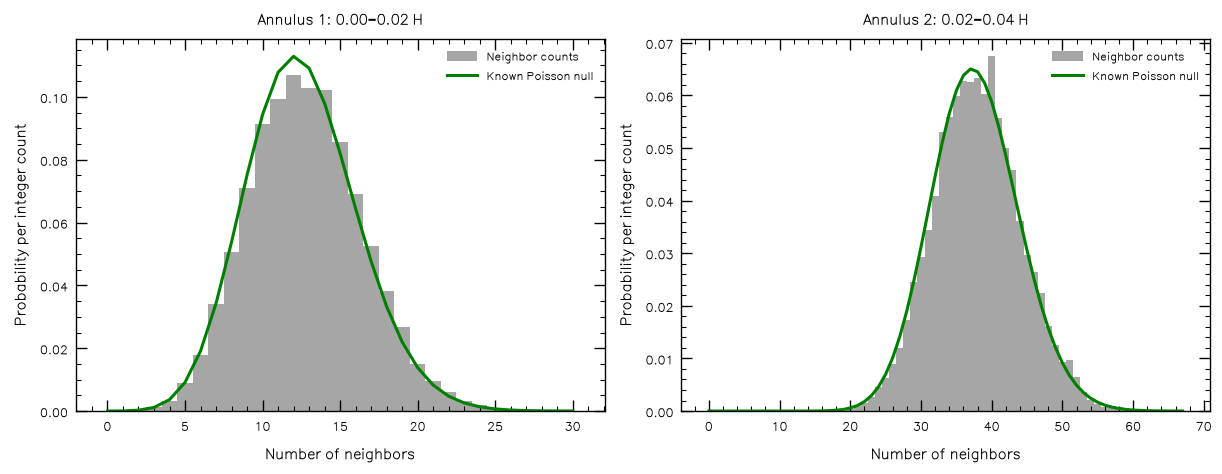

In [5]:
def poisson_logpmf(k, lam):
    '''Log probability of a non-negative integer count, with broadcastable means.'''
    k = np.asarray(k)
    lam = np.asarray(lam)
    if (not np.all(np.isfinite(k)) or np.any(k < 0) or np.any(k != np.floor(k))
            or not np.all(np.isfinite(lam)) or np.any(lam < 0)):
        raise ValueError("Counts must be non-negative integers and means finite/non-negative.")
    return xlogy(k, lam) - lam - gammaln(k + 1)

def poisson_pmf(k, lam):
    return np.exp(poisson_logpmf(k, lam))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for j, ax in enumerate(axes):
    values = background_counts[:, j]
    k = np.arange(0, max(values.max() + 1, int(LAMBDA[j] + 5 * np.sqrt(LAMBDA[j]))))
    bins = np.arange(-0.5, k[-1] + 1.5)
    ax.hist(values, bins=bins, density=True, alpha=0.35, label="Neighbor counts")
    ax.plot(k, poisson_pmf(k, LAMBDA[j]), color="C3", lw=2, label="Known Poisson null")
    ax.set(xlabel="Number of neighbors", ylabel="Probability per integer count",
           title=f"Annulus {j + 1}: {RADII[j]:.2f}–{RADII[j + 1]:.2f} H")
    ax.legend(fontsize=9)
    print(f"Annulus {j + 1}: expected mean {LAMBDA[j]:.3f}; "
          f"measured mean {values.mean():.3f}; variance {values.var():.3f}")
finish(fig, "03_poisson_marginals")

The empirical distributions should be close to their Poisson predictions, not
identical. Their means differ because the annular areas differ. Their variances
are comparable to their means.

The many overlapping apertures do not supply as much independent information
as their row count suggests. We will not multiply these rows into an ordinary
independent-data likelihood or attach independent-sample error bars to them.

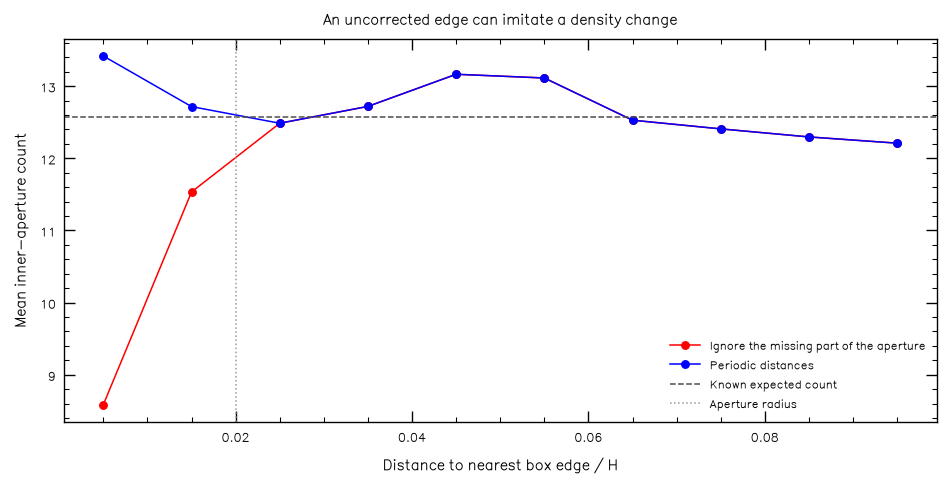

In [6]:
unwrapped_counts = neighbor_counts(background, RADII, L, periodic=False)
edge_distance = np.min(np.column_stack([background, L - background]), axis=1)
edges = np.linspace(0.0, 0.10, 11)
midpoints = (edges[:-1] + edges[1:]) / 2

fig, ax = plt.subplots(figsize=(8.5, 4.3), layout="constrained")
for counts, label, color in [
    (unwrapped_counts[:, 0], "Ignore the missing part of the aperture", "C2"),
    (background_counts[:, 0], "Periodic distances", "C1"),
]:
    means = [counts[(edge_distance >= a) & (edge_distance < b)].mean()
             for a, b in zip(edges[:-1], edges[1:])]
    ax.plot(midpoints, means, "o-", label=label, color=color)
ax.axhline(LAMBDA[0], color="0.3", ls="--", label="Known expected count")
ax.axvline(RADII[1], color="0.6", ls=":", label="Aperture radius")
ax.set(xlabel="Distance to nearest box edge / H", ylabel="Mean inner-aperture count",
       title="An uncorrected edge can imitate a density change")
ax.legend(fontsize=9, loc="lower right")
finish(fig, "04_boundary_effect")

Farther than one aperture radius from an edge, ordinary and periodic counts
agree. Near an edge, the uncorrected aperture misses particles. Periodicity
removes that particular bias for our synthetic torus.

For a real disk image, wrapping one side to the other is generally inappropriate.
One would instead restrict the analysis to complete apertures, calculate
effective areas, or model the observational window.

## 3. Joint and conditional distributions

Let $N_1$ and $N_2$ be counts in the two disjoint annuli at a **fixed** center.
Their joint distribution describes pairs of counts; the marginals obey

$$p(N_1)=\sum_{N_2}p(N_1,N_2).$$

Under a homogeneous Poisson process, disjoint-region counts are independent:

$$p(N_1,N_2)=p(N_1)p(N_2),\qquad
p(N_2\mid N_1)=p(N_2).$$

We now generate 4,000 independent realizations around the same center. Only
particles inside the largest circle matter. In each realization we draw their
total from a Poisson distribution and place them uniformly in that circle.
Uniform area requires $r=r_{\max}\sqrt{U}$, not $r=r_{\max}U$.
This is a direct spatial experiment, not a resampling of overlapping apertures.

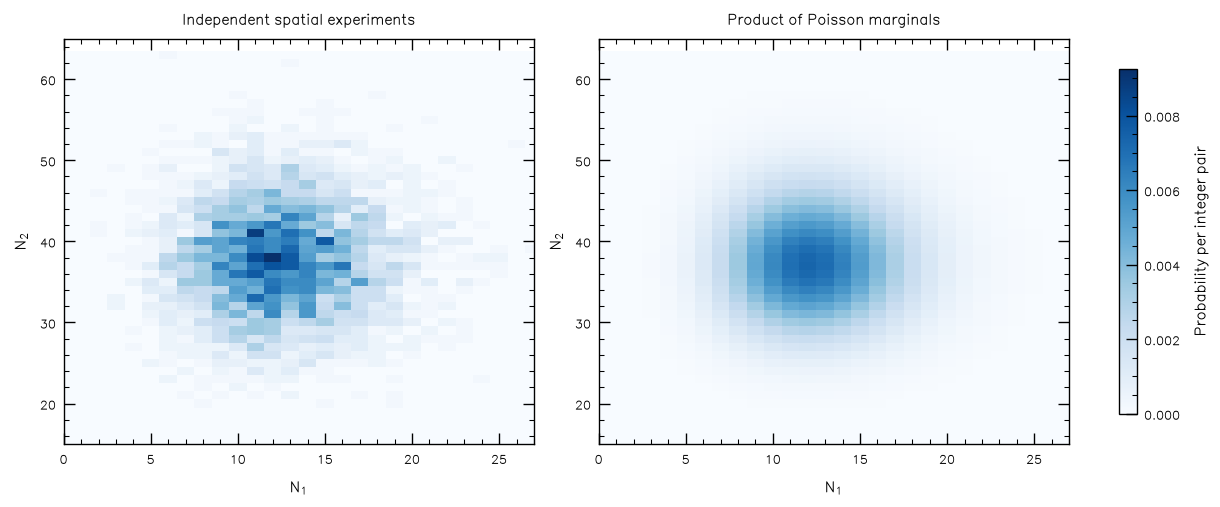

Empirical correlation of independent annular counts: 0.020


In [7]:
rng_annuli = np.random.default_rng(seeds["annuli"])
n_realizations = 4_000
ensemble_counts = np.zeros((n_realizations, 2), dtype=int)
for i in range(n_realizations):
    n_outer_disk = rng_annuli.poisson(RHO * np.pi * RADII[-1]**2)
    r = RADII[-1] * np.sqrt(rng_annuli.random(n_outer_disk))
    theta = rng_annuli.uniform(0, 2 * np.pi, n_outer_disk)
    positions = np.column_stack([r * np.cos(theta), r * np.sin(theta)])
    radial_distance = np.linalg.norm(positions, axis=1)
    ensemble_counts[i] = np.histogram(radial_distance, bins=RADII)[0]

k1 = np.arange(ensemble_counts[:, 0].max() + 1)
k2 = np.arange(ensemble_counts[:, 1].max() + 1)
joint, _, _ = np.histogram2d(
    ensemble_counts[:, 0], ensemble_counts[:, 1],
    bins=[np.arange(-0.5, k1[-1] + 1.5), np.arange(-0.5, k2[-1] + 1.5)],
)
joint /= n_realizations
joint_null = np.outer(poisson_pmf(k1, LAMBDA[0]), poisson_pmf(k2, LAMBDA[1]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
for ax, matrix, title in zip(
    axes, [joint, joint_null], ["Independent spatial experiments", "Product of Poisson marginals"]
):
    im = ax.imshow(matrix.T, origin="lower", aspect="auto", cmap="Blues",
                   extent=[-0.5, k1[-1] + 0.5, -0.5, k2[-1] + 0.5],
                   vmin=0, vmax=max(joint.max(), joint_null.max()))
    ax.set(xlabel=r"$N_1$", ylabel=r"$N_2$", title=title, xlim=(0, 27), ylim=(15, 65))
fig.colorbar(im, ax=axes, label="Probability per integer pair", shrink=0.85)
finish(fig, "05_joint_distribution")
corr = np.corrcoef(ensemble_counts.T)[0, 1]
print(f"Empirical correlation of independent annular counts: {corr:.3f}")

The empirical joint distribution is noisy, but its shape should resemble the
product prediction. A correlation near zero is consistent with independence;
zero correlation alone would not prove independence for an arbitrary process.
Here independence is a property of the specified Poisson model.

**Predict:** If we retain only realizations with a larger inner count, should
the mean outer count change systematically under this null?

N1 = 10: conditional mean N2 = 37.92; theoretical mean = 37.70
N1 = 15: conditional mean N2 = 38.04; theoretical mean = 37.70


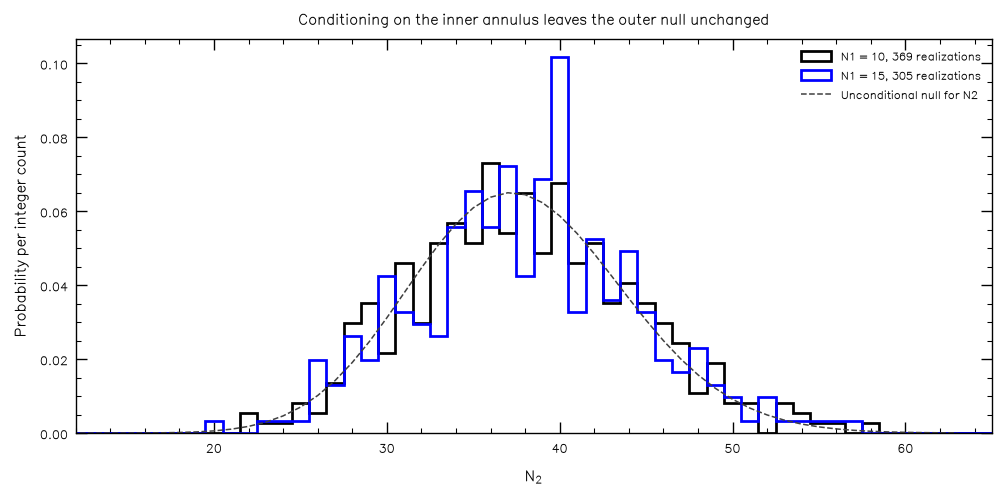

In [8]:
conditioning_values = np.rint(np.quantile(ensemble_counts[:, 0], [0.25, 0.75])).astype(int)
fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
bins = np.arange(10.5, max(ensemble_counts[:, 1].max(), 65) + 1.5)
for n1 in conditioning_values:
    conditional = ensemble_counts[ensemble_counts[:, 0] == n1, 1]
    ax.hist(conditional, bins=bins, density=True, histtype="step", lw=1.8,
            label=f"N1 = {n1}, {len(conditional)} realizations")
    print(f"N1 = {n1}: conditional mean N2 = {conditional.mean():.2f}; "
          f"theoretical mean = {LAMBDA[1]:.2f}")
ax.plot(k2, poisson_pmf(k2, LAMBDA[1]), "--", color="0.25", label="Unconditional null for N2")
ax.set(xlabel=r"$N_2$", ylabel="Probability per integer count",
       title="Conditioning on the inner annulus leaves the outer null unchanged",
       xlim=(12, 65))
ax.legend(fontsize=9)
finish(fig, "06_conditional_distribution")

The conditional histograms fluctuate because they contain fewer realizations.
They should nonetheless be compatible with the same outer-annulus distribution.

This independence concerns disjoint regions at a given location in the specified
null process. It does not apply to nested circles or to apertures that overlap
at different centers. A structured alternative can produce correlated counts
when we sample centers across regions of different intensity.

## 4. Injecting dust concentrations

We keep the background realization and add two compact populations:

$$\boldsymbol{x}_i\sim\mathcal{N}(\boldsymbol{\mu}_c,\sigma_c^2 I),
\qquad \boldsymbol{x}_i\mapsto\boldsymbol{x}_i\bmod L.$$

The modulo keeps every coordinate in the periodic square. Clump A has 200
tracers and $\sigma_A=0.020H$; clump B has 100 and $\sigma_B=0.015H$.
The fixed injection populations are not claimed to follow the Poisson null.

The origin labels are stored so that we can evaluate the experiment. The
neighbor-count detector receives **coordinates only**.

**Predict:** Will every injected tracer have the same neighbor count? Can a
background-origin tracer also lie in an overdense aperture?

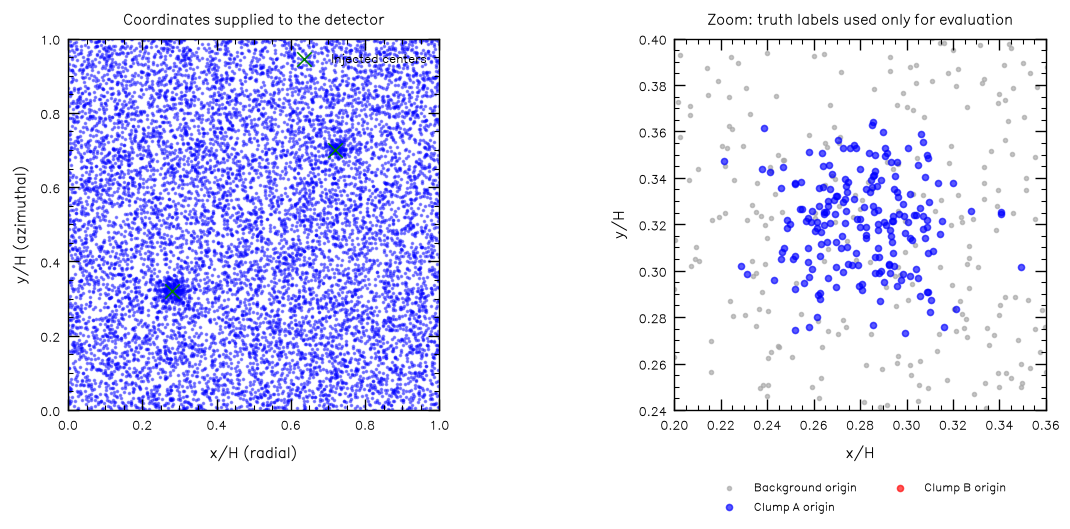

Total particles: 10,385; injected populations: [200, 100]


In [9]:
CLUMP_CENTERS = np.array([[0.28, 0.32], [0.72, 0.70]])
CLUMP_SIGMAS = np.array([0.020, 0.015])
CLUMP_POPULATIONS = np.array([200, 100])
rng_clumps = np.random.default_rng(seeds["clumps"])

clumps = [
    rng_clumps.normal(center, sigma, size=(int(n), 2)) % L
    for center, sigma, n in zip(CLUMP_CENTERS, CLUMP_SIGMAS, CLUMP_POPULATIONS)
]
particles = np.vstack([background, *clumps])
origin = np.concatenate([np.zeros(len(background), dtype=int),
                         np.ones(CLUMP_POPULATIONS[0], dtype=int),
                         np.full(CLUMP_POPULATIONS[1], 2, dtype=int)])
scene_counts = neighbor_counts(particles, RADII, L)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.7), layout="constrained")
axes[0].scatter(particles[:, 0], particles[:, 1], s=2, alpha=0.4, color="C1")
patch_axes(axes[0])
axes[0].scatter(*CLUMP_CENTERS.T, marker="x", s=90, color="C3", label="Injected centers")
axes[0].legend(loc="upper right")
axes[0].set_title("Coordinates supplied to the detector")
for group, label, color, size in [
    (0, "Background origin", "0.65", 7),
    (1, "Clump A origin", "C1", 16),
    (2, "Clump B origin", "C2", 16),
]:
    subset = particles[origin == group]
    axes[1].scatter(subset[:, 0], subset[:, 1], s=size, color=color, alpha=0.65, label=label)
axes[1].set(xlabel=r"$x/H$", ylabel=r"$y/H$", title="Zoom: truth labels used only for evaluation",
            xlim=(0.20, 0.36), ylim=(0.24, 0.40))
axes[1].set_aspect("equal")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=9)
finish(fig, "07_injected_clumps")
print(f"Total particles: {len(particles):,}; injected populations: {CLUMP_POPULATIONS.tolist()}")

### Likelihood analysis

At the main search radius $r=0.02H$, the null expectation is still the
**background** expectation, $\lambda_{\rm bg}=\rho\pi r^2$.
We do not estimate that expectation from the locally enhanced count.

For each tracer, evaluate

$$\ell_i=\log P(N_i=k_i\mid\lambda_{\rm bg}).$$

A large count has a small probability under this null. The log scale makes
those small probabilities easy to compare. The right-hand panel below smooths
the discrete background scores only to help visualize their distribution; that
smoothing is not part of the detector.

Background origin: mean inner count = 13.15
Clump A origin: mean inner count = 50.56
Clump B origin: mean inner count = 51.96


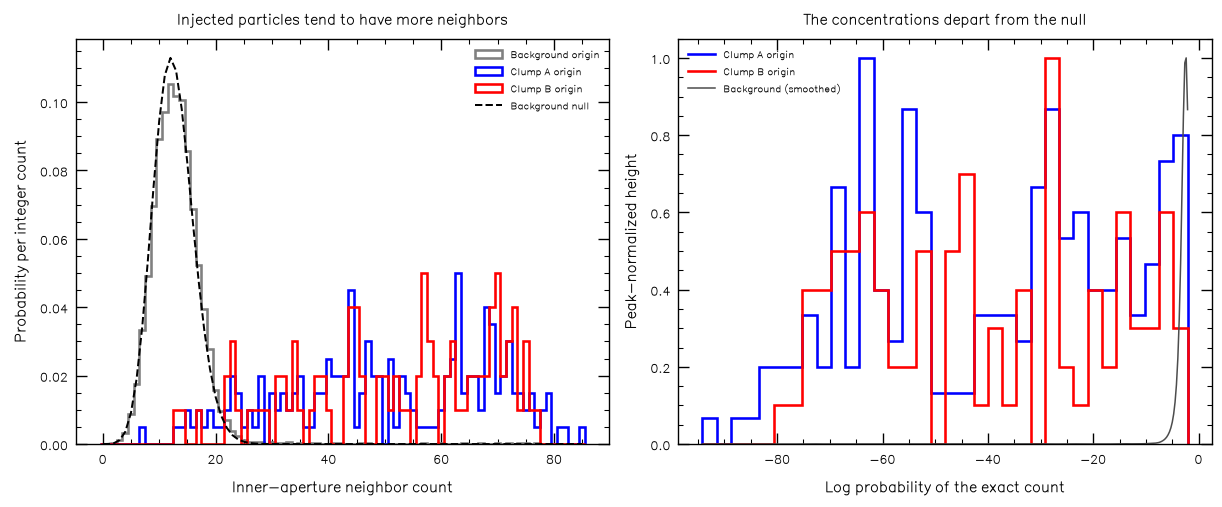

In [10]:
lambda_bg = float(LAMBDA[0])
inner_counts = scene_counts[:, 0]
log_likelihood = poisson_logpmf(inner_counts, lambda_bg)
group_names = ["Background origin", "Clump A origin", "Clump B origin"]
group_colors = ["0.5", "C1", "C2"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
k_scene = np.arange(inner_counts.max() + 1)
for group, label, color in zip(range(3), group_names, group_colors):
    selected = origin == group
    axes[0].hist(inner_counts[selected], bins=np.arange(-0.5, k_scene[-1] + 1.5),
                 density=True, histtype="step", lw=1.7, color=color, label=label)
    print(f"{label}: mean inner count = {inner_counts[selected].mean():.2f}")
axes[0].plot(k_scene, poisson_pmf(k_scene, lambda_bg), "k--", lw=1.3, label="Background null")
axes[0].set(xlabel="Inner-aperture neighbor count", ylabel="Probability per integer count",
            title="Injected particles tend to have more neighbors")
axes[0].legend(fontsize=8)

ll_bins = np.linspace(log_likelihood.min() - 1, log_likelihood.max() + 0.1, 35)
centers_ll = (ll_bins[1:] + ll_bins[:-1]) / 2
for group in [1, 2]:
    hist, _ = np.histogram(log_likelihood[origin == group], bins=ll_bins)
    axes[1].stairs(hist / hist.max(), ll_bins, color=group_colors[group],
                   label=group_names[group], lw=1.7)
xx = np.linspace(ll_bins[0], ll_bins[-1], 350)
kde = gaussian_kde(log_likelihood[origin == 0])
smooth = kde(xx)
axes[1].plot(xx, smooth / smooth.max(), color="0.3", label="Background (smoothed)")
axes[1].set(xlabel="Log probability of the exact count", ylabel="Peak-normalized height",
            title="The concentrations depart from the null")
axes[1].legend(fontsize=8)
finish(fig, "08_counts_and_likelihoods")

The injected populations should be shifted toward larger counts and more
negative log probabilities. Their outskirts can overlap the background
distribution. Meanwhile a background-origin tracer near an injected center
also sees the enhanced neighborhood. Origin is not the same as local environment.

There is an additional distinction: $P(N=k\mid\lambda)$ describes exactly one
count. It is small for sufficiently low counts too. To search specifically
for **excesses**, calculate

$$p_{\rm local}=P(N\ge k\mid\lambda_{\rm bg})
=\sum_{n=k}^{\infty}P(N=n\mid\lambda_{\rm bg}).$$

This is a one-sided null tail probability. It is not the probability that a
clump is absent, nor a posterior probability that a clump is real.

In [11]:
example_counts = np.array([0, 13, 30, 60])
display(Markdown("| k | P(N = k) | P(N ≥ k) |\n|---:|---:|---:|\n" + "\n".join(
    f"| {k} | {poisson_pmf(k, lambda_bg):.3g} | {poisson.sf(k - 1, lambda_bg):.3g} |"
    for k in example_counts
)))

| k | P(N = k) | P(N ≥ k) |
|---:|---:|---:|
| 0 | 3.49e-06 | 1 |
| 13 | 0.109 | 0.489 |
| 30 | 1.24e-05 | 2.07e-05 |
| 60 | 3.76e-22 | 4.73e-22 |

### Construct a spatial detection map

Place a regular grid of aperture centers over the patch, using cell midpoints
so that the periodic endpoint is not duplicated. The counts here include all
particles within each aperture: a grid location is not a particle to subtract.

The left map retains the textbook's exact-count log-likelihood construction.
The right map displays $-\log_{10}p_{\rm local}$, which increases for stronger
excesses.

We prespecify this 60-by-60 grid and the main radius. For a known correct
background rate, a conservative whole-map threshold is
$p_{\rm local}\le 0.05/M$, where $M$ is the number of tested grid positions.
This Bonferroni bound does not require independent apertures. It controls the
probability of one or more false flags under the global uniform null, not
the probability that a physical interpretation is correct.

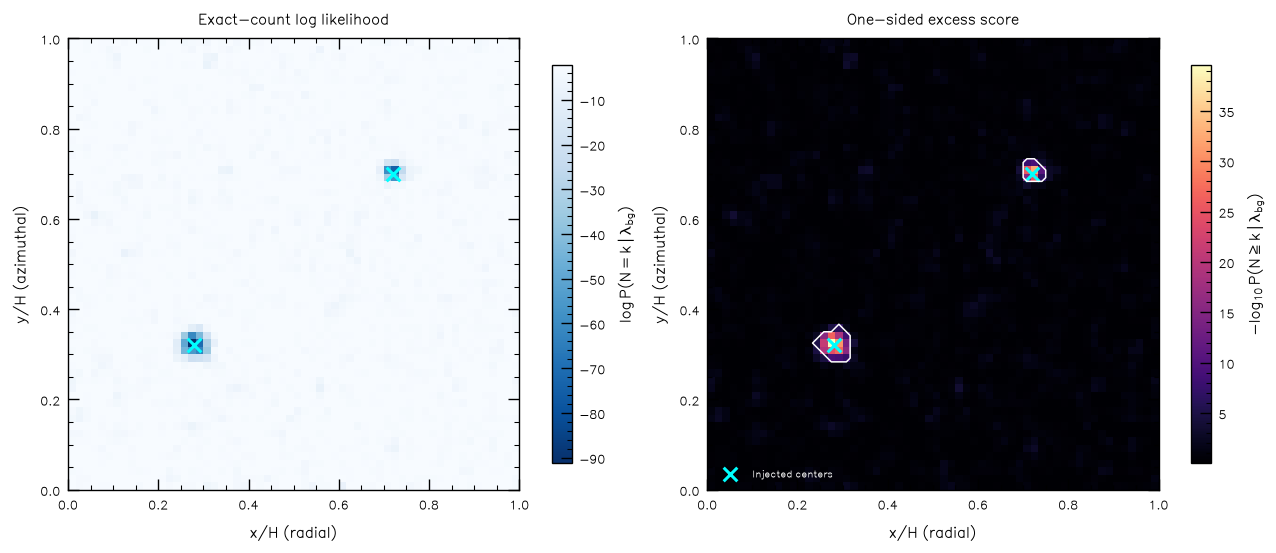

Local probability threshold: 1.39e-05 for 3,600 positions
Flagged grid positions: 25 (not a count of distinct clumps)


In [12]:
GRID_SIZE = 60
grid_edges = np.linspace(0, L, GRID_SIZE + 1)
grid_axis = (grid_edges[:-1] + grid_edges[1:]) / 2
GX, GY = np.meshgrid(grid_axis, grid_axis)
grid_centers = np.column_stack([GX.ravel(), GY.ravel()])
grid_counts = aperture_counts(particles, grid_centers, RADII[1], L)
grid_ll = poisson_logpmf(grid_counts, lambda_bg).reshape(GX.shape)
local_p = poisson.sf(grid_counts - 1, lambda_bg).reshape(GX.shape)
excess_score = (-poisson.logsf(grid_counts - 1, lambda_bg) / np.log(10)).reshape(GX.shape)

ALPHA = 0.05
threshold = ALPHA / len(grid_centers)
flagged = local_p <= threshold

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5), layout="constrained")
for ax, values, title, label, cmap in [
    (axes[0], grid_ll, "Exact-count log likelihood", r"$\log P(N=k\mid\lambda_{\rm bg})$", "Blues_r"),
    (axes[1], excess_score, "One-sided excess score", r"$-\log_{10}P(N\geq k\mid\lambda_{\rm bg})$", "magma"),
]:
    mesh = ax.pcolormesh(grid_edges, grid_edges, values, shading="flat", cmap=cmap)
    ax.scatter(*CLUMP_CENTERS.T, color="cyan", marker="x", s=80, lw=2, label="Injected centers")
    patch_axes(ax)
    ax.set_title(title)
    fig.colorbar(mesh, ax=ax, shrink=0.80, label=label)
axes[1].contour(GX, GY, flagged.astype(float), levels=[0.5], colors="white", linewidths=1)
axes[1].legend(loc="lower left", fontsize=8, labelcolor="white")
finish(fig, "09_detection_maps")
print(f"Local probability threshold: {threshold:.3g} for {len(grid_centers):,} positions")
print(f"Flagged grid positions: {flagged.sum()} (not a count of distinct clumps)")

The injected centers should coincide with likelihood depressions and strong
upper-tail excesses. Adjacent flagged apertures sample the same structure;
they are not distinct detections.

The threshold above is valid for this prespecified map with a known uniform
rate. If we estimate the rate from noisy data, select a radius after viewing
the maps, or scan additional maps, the stated family of tests changes.
Calibration must include those choices. A null simulation of the complete
search procedure is a useful next step.

## 5. Considerations on the method

### The analysis scale is a scientific choice

A tiny aperture contains few particles even inside a broad concentration.
A very large aperture mixes concentrated material with much more background.
We compare three radii below. These are exploratory maps, not three independent
confirmations of a detection and not an additional calibrated multi-scale search.

**Predict:** Which radius will make the broad clump look most compact? Will
the radius that gives the smallest tail probability necessarily equal its
Gaussian width?

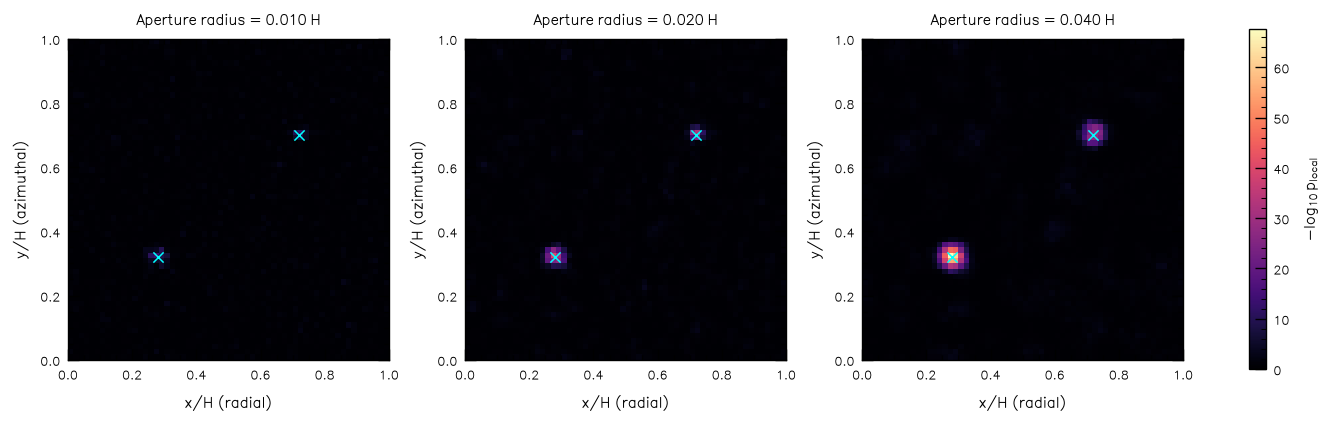

In [13]:
search_radii = [0.01, 0.02, 0.04]
scale_scores = []
for radius in search_radii:
    counts = aperture_counts(particles, grid_centers, radius, L)
    mean_null = RHO * np.pi * radius**2
    scale_scores.append((-poisson.logsf(counts - 1, mean_null) / np.log(10)).reshape(GX.shape))

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), layout="constrained")
vmax = max(score.max() for score in scale_scores)
for ax, radius, score in zip(axes, search_radii, scale_scores):
    im = ax.pcolormesh(grid_edges, grid_edges, score, cmap="magma", vmin=0, vmax=vmax)
    ax.scatter(*CLUMP_CENTERS.T, marker="x", color="cyan", s=45)
    patch_axes(ax)
    ax.set_title(f"Aperture radius = {radius:.3f} H")
fig.colorbar(im, ax=axes, shrink=0.75, label=r"$-\log_{10}p_{\rm local}$")
finish(fig, "10_aperture_scales")

The apparent width and strength depend on the aperture. A large signal-to-noise
aperture need not be an unbiased size estimator. Nested apertures also share
particles and therefore have correlated counts.

### What the null model does and does not establish

- **Nonuniform background:** A radial gradient, a pressure bump, or a broad ring
  can violate the constant-$\rho$ model. A local or inhomogeneous intensity model
  would then be needed.
- **Correlated particles:** Real dust and numerical superparticles need not be
  independent tracers. Their count variance can exceed a Poisson expectation.
  A poor null can make ordinary structure appear excessively significant.
- **Sampling resolution:** Counts depend on the number and weights of numerical
  tracers. Changing simulation resolution does not automatically add independent
  physical evidence. Unequal-weight mass sums are not ordinary Poisson counts.
- **Projection and dynamics:** This is a two-dimensional snapshot. It does not
  measure a three-dimensional density or compare it with a collapse threshold.
- **Observations:** ALMA continuum pixels measure brightness with beam-correlated
  noise. They are not the independent particle counts used in this notebook.

A departure from this null establishes a statistical concentration relative to
this model. Identifying streaming instability or planetesimal formation needs
additional physical evidence.

## 6. Maximum likelihood estimation of the background rate

Until now the detector knew $\rho$. In an application we would have to estimate
it. To teach that step with a valid factorized likelihood, generate an
**independent control field** containing only the homogeneous background and
divide it into disjoint cells of equal area $A_{\rm cell}$.

Unlike the overlapping neighbor apertures, these cell counts are independent
under the Poisson process:

$$C_i\sim\operatorname{Poisson}(\lambda_{\rm cell}),\qquad
\lambda_{\rm cell}=\rho A_{\rm cell}.$$

The control is a deliberately available simulated reference, not something
automatically known in a real disk. A real reference region must be selected
and its representativeness checked without using unavailable truth labels.

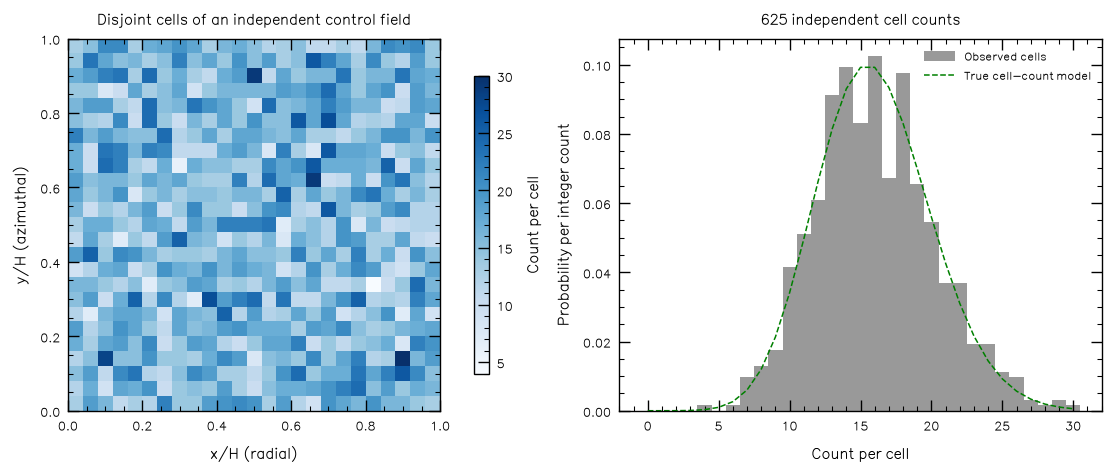

In [14]:
control = generate_poisson_patch(RHO, L, np.random.default_rng(seeds["control"]))
CELLS_PER_SIDE = 25
cell_edges = np.linspace(0, L, CELLS_PER_SIDE + 1)
control_count_map, _, _ = np.histogram2d(
    control[:, 0], control[:, 1], bins=[cell_edges, cell_edges]
)
control_counts = control_count_map.astype(int).ravel()
cell_area = (L / CELLS_PER_SIDE)**2
lambda_cell_true = RHO * cell_area

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), layout="constrained")
im = axes[0].pcolormesh(cell_edges, cell_edges, control_count_map.T, cmap="Blues")
patch_axes(axes[0])
axes[0].set_title("Disjoint cells of an independent control field")
fig.colorbar(im, ax=axes[0], label="Count per cell", shrink=0.8)
k_control = np.arange(control_counts.max() + 1)
axes[1].hist(control_counts, bins=np.arange(-0.5, k_control[-1] + 1.5),
             density=True, alpha=0.4, label="Observed cells")
axes[1].plot(k_control, poisson_pmf(k_control, lambda_cell_true), "--", color="C3",
             label="True cell-count model")
axes[1].set(xlabel="Count per cell", ylabel="Probability per integer count",
            title=f"{len(control_counts)} independent cell counts")
axes[1].legend(fontsize=9)
finish(fig, "11_control_field")

For $m$ independent counts, the likelihood and its logarithm are

$$L(\lambda)=\prod_{i=1}^m\frac{\lambda^{C_i}e^{-\lambda}}{C_i!},$$
$$\ell(\lambda)=\left(\sum_i C_i\right)\log\lambda-m\lambda
-\sum_i\log(C_i!).$$

Setting $d\ell/d\lambda=0$ gives

$$\widehat{\lambda}_{\rm cell}=\frac{1}{m}\sum_i C_i=\overline C,\qquad
\widehat{\rho}=\frac{\overline C}{A_{\rm cell}}.$$

We evaluate a grid first and check it against this analytic result. Maximum
likelihood itself uses no prior. A uniform prior can make a posterior mode
coincide with the MLE in suitable parameterizations, but is a separate choice.

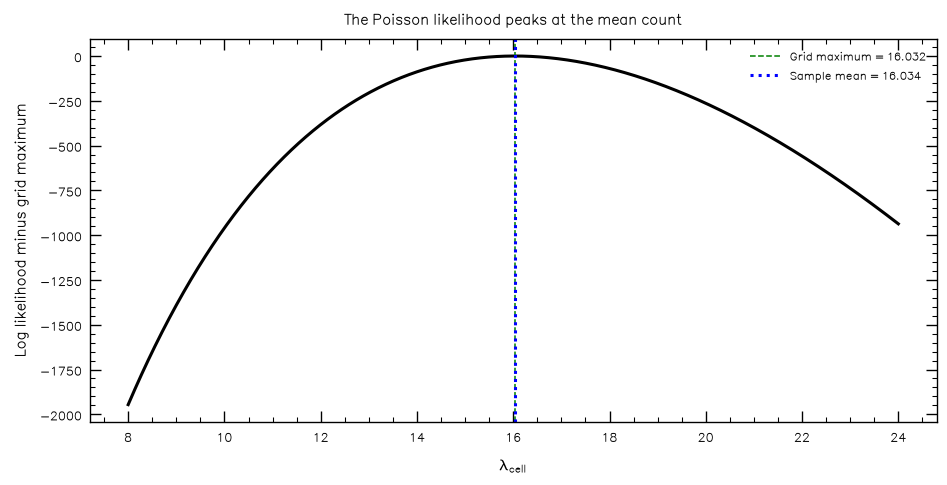

True cell mean:          16.000
Analytic MLE:            16.034
Grid MLE:                16.032
Estimated intensity:     10,021 ± 100 tracers per H^2 (approx. 1 SE)
Estimated aperture mean: 12.593; known value 12.566
Whole injected field:    10,385 tracers per H^2


In [15]:
lambda_hat = float(control_counts.mean())
lambda_grid = np.linspace(0.5 * lambda_cell_true, 1.5 * lambda_cell_true, 1501)
control_ll = poisson_logpmf(control_counts[None, :], lambda_grid[:, None]).sum(axis=1)
lambda_grid_hat = float(lambda_grid[np.argmax(control_ll)])
rho_hat = lambda_hat / cell_area
rho_se = np.sqrt(len(control)) / L**2  # Plug-in standard error of N_control / area
lambda_aperture_hat = rho_hat * AREAS[0]

fig, ax = plt.subplots(figsize=(8.5, 4.3), layout="constrained")
ax.plot(lambda_grid, control_ll - control_ll.max(), lw=2)
ax.axvline(lambda_grid_hat, color="C3", ls="--", label=f"Grid maximum = {lambda_grid_hat:.3f}")
ax.axvline(lambda_hat, color="C1", ls=":", lw=2, label=f"Sample mean = {lambda_hat:.3f}")
ax.set(xlabel=r"$\lambda_{\rm cell}$", ylabel="Log likelihood minus grid maximum",
       title="The Poisson likelihood peaks at the mean count")
ax.legend(fontsize=9)
finish(fig, "12_poisson_mle")

print(f"True cell mean:          {lambda_cell_true:.3f}")
print(f"Analytic MLE:            {lambda_hat:.3f}")
print(f"Grid MLE:                {lambda_grid_hat:.3f}")
print(f"Estimated intensity:     {rho_hat:,.0f} ± {rho_se:,.0f} tracers per H^2 (approx. 1 SE)")
print(f"Estimated aperture mean: {lambda_aperture_hat:.3f}; known value {lambda_bg:.3f}")
print(f"Whole injected field:    {len(particles) / L**2:,.0f} tracers per H^2")

The grid maximum and sample mean agree to the grid resolution. Convert a fitted
cell mean to an aperture expectation through the ratio of their areas; do not
substitute $\lambda_{\rm cell}$ directly into an aperture likelihood.

The whole injected field has a larger density than the independent control.
Estimating the background from all particles would absorb some injected signal.
Our control avoids that contamination by construction.

The estimated rate has uncertainty. Substituting it into the known-rate
Bonferroni calculation would not automatically preserve the earlier guarantee.
One can propagate control-rate uncertainty or calibrate the full detection
procedure with independent null realizations. Those are extensions beyond the
main exercise.

## 7. Save the data and check the experiment

The following exports make the tutorial independently inspectable. They include
coordinates, generating-component labels, disjoint control counts, all generating
parameters, and SHA-256 file hashes. The labels remain evaluation information.
We then check the numerical probability calculation, spatial geometry, null
statistics, and recovery of both injected centers.

In [16]:
np.savetxt(DATA / "background.csv", background, delimiter=",",
           header="x_over_H,y_over_H", comments="", fmt="%.12f")
np.savetxt(DATA / "particles_with_clumps.csv", np.column_stack([particles, origin]),
           delimiter=",", header="x_over_H,y_over_H,origin", comments="",
           fmt=["%.12f", "%.12f", "%d"])
np.savetxt(DATA / "control_points.csv", control, delimiter=",",
           header="x_over_H,y_over_H", comments="", fmt="%.12f")
cell_ids = np.indices(control_count_map.shape).reshape(2, -1).T
np.savetxt(DATA / "control_cell_counts.csv", np.column_stack([cell_ids, control_counts]),
           delimiter=",", header="x_cell_index,y_cell_index,count", comments="", fmt="%d")

data_files = ["background.csv", "particles_with_clumps.csv",
              "control_points.csv", "control_cell_counts.csv"]
file_hashes = {name: hashlib.sha256((DATA / name).read_bytes()).hexdigest() for name in data_files}
provenance = {
    "data_kind": "synthetic teaching data, not observations or hydrodynamic outputs",
    "generator": "poisson_dust_clumps.ipynb",
    "base_seed": SEED, "seeds": seeds, "bit_generator": "PCG64",
    "coordinates": "dimensionless x/H and y/H; equal numerical tracer weights",
    "box_side_over_H": L, "background_intensity_per_H2": RHO,
    "background_population": len(background), "control_population": len(control),
    "annular_edges_over_H": RADII.tolist(),
    "clump_centers_over_H": CLUMP_CENTERS.tolist(),
    "clump_sigma_over_H": CLUMP_SIGMAS.tolist(),
    "clump_populations": CLUMP_POPULATIONS.tolist(),
    "origin_labels": {"0": "background", "1": "clump A", "2": "clump B"},
    "boundary": "ordinary doubly periodic square, not shearing-box dynamics",
    "grid_size": GRID_SIZE, "main_search_radius_over_H": float(RADII[1]),
    "familywise_alpha_known_null": ALPHA, "control_cells_per_side": CELLS_PER_SIDE,
    "python_version": platform.python_version(),
    "packages": {name: importlib.metadata.version(name)
                 for name in ["numpy", "scipy", "matplotlib", "matplotidlib"]},
    "plot_style": {"package": "matplotidlib", "selected_font": STYLE_FONT},
    "file_sha256": file_hashes,
    "scientific_references": [
        "https://arxiv.org/abs/astro-ph/0409263",
        "https://arxiv.org/abs/astro-ph/0702626",
    ],
}
(DATA / "provenance.json").write_text(json.dumps(provenance, indent=2, sort_keys=True) + "\n")
print("Exported:", ", ".join(data_files), "and provenance.json")

Exported: background.csv, particles_with_clumps.csv, control_points.csv, control_cell_counts.csv and provenance.json


In [17]:
# Hand-solvable periodic geometry: one wrapped neighbor and one farther neighbor.
toy = np.array([[0.0, 0.0], [0.875, 0.0], [0.25, 0.0], [0.0, 0.5]])
toy_counts = neighbor_counts(toy, np.array([0.0, 0.2, 0.4]), L)
toy_unwrapped = neighbor_counts(toy, np.array([0.0, 0.2, 0.4]), L, periodic=False)

# Independently reconstruct several full-field counts by direct distances.
brute_counts = []
for i in [0, 1, 17, 100, len(background) - 1]:
    dxy = (background - background[i] + L / 2) % L - L / 2
    rr = np.linalg.norm(dxy, axis=1)
    rr[i] = np.inf
    brute_counts.append([np.sum((rr >= a) & (rr < b))
                         for a, b in zip(RADII[:-1], RADII[1:])])
indices = [0, 1, 17, 100, len(background) - 1]

nearest_center_indices = np.argmin(
    ((grid_centers[:, None, :] - CLUMP_CENTERS[None, :, :])**2).sum(axis=2), axis=0
)
center_pvalues = local_p.ravel()[nearest_center_indices]
grid_step = lambda_grid[1] - lambda_grid[0]
saved_scene = np.loadtxt(DATA / "particles_with_clumps.csv", delimiter=",", skiprows=1)

checks = {
    "pmf_matches_scipy": np.allclose(poisson_logpmf(np.arange(80), lambda_bg),
                                     poisson.logpmf(np.arange(80), lambda_bg), atol=1e-12),
    "pmf_normalizes": np.isclose(poisson_pmf(np.arange(200), lambda_bg).sum(), 1, atol=1e-12),
    "zero_rate_has_correct_support": poisson_logpmf(0, 0) == 0 and np.isneginf(poisson_logpmf(1, 0)),
    "outer_annulus_has_three_times_area": np.isclose(AREAS[1] / AREAS[0], 3),
    "periodic_wrap_and_self_exclusion": np.array_equal(toy_counts[0], [1, 1]),
    "ordinary_edges_differ_as_expected": np.array_equal(toy_unwrapped[0], [0, 1]),
    "tree_matches_direct_geometry": np.array_equal(brute_counts, background_counts[indices]),
    "independent_ensemble_means_match": np.all(
        np.abs(ensemble_counts.mean(axis=0) - LAMBDA) < 6 * np.sqrt(LAMBDA / n_realizations)
    ),
    "independent_ensemble_variances_match": np.all(
        np.abs(ensemble_counts.var(axis=0) / LAMBDA - 1) < 0.10
    ),
    "independent_annuli_have_small_correlation": abs(corr) < 0.06,
    "joint_probability_normalizes": np.isclose(joint.sum(), 1),
    "both_injected_centers_flagged": np.all(center_pvalues <= threshold),
    "poisson_grid_mle_matches_sample_mean": abs(lambda_grid_hat - lambda_hat) <= grid_step,
    "control_rate_consistent_with_generating_rate": abs(rho_hat - RHO) < 6 * np.sqrt(RHO / L**2),
    "control_counts_preserve_population": control_counts.sum() == len(control),
    "exported_coordinates_roundtrip": np.allclose(saved_scene[:, :2], particles, atol=1e-12, rtol=0),
    "exported_truth_labels_roundtrip": np.array_equal(saved_scene[:, 2].astype(int), origin),
    "coordinates_within_periodic_domain": np.all((particles >= 0) & (particles < L)),
    "tail_probability_monotone": np.all(np.diff(poisson.sf(np.arange(100) - 1, lambda_bg)) <= 0),
}
checks = {key: bool(value) for key, value in checks.items()}
report = {
    "all_passed": all(checks.values()), "checks": checks,
    "metrics": {
        "background_population": len(background), "scene_population": len(particles),
        "ensemble_means": ensemble_counts.mean(axis=0).tolist(),
        "ensemble_variances": ensemble_counts.var(axis=0).tolist(),
        "ensemble_correlation": float(corr),
        "center_local_pvalues": center_pvalues.tolist(),
        "known_null_map_threshold": float(threshold),
        "flagged_grid_positions": int(flagged.sum()),
        "lambda_cell_analytic_mle": lambda_hat, "lambda_cell_grid_mle": lambda_grid_hat,
        "estimated_background_intensity": float(rho_hat),
    },
}
(TUTORIAL_DIR / "verification.json").write_text(json.dumps(report, indent=2, sort_keys=True) + "\n")
for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name}")
assert report["all_passed"], "A numerical check failed. Inspect verification.json."
display(Markdown(
    f"**All {len(checks)} checks passed.** "
    f"The nearest grid apertures to injected centers A and B have local tail probabilities "
    f"{center_pvalues[0]:.2e} and {center_pvalues[1]:.2e}."
))

PASS  pmf_matches_scipy
PASS  pmf_normalizes
PASS  zero_rate_has_correct_support
PASS  outer_annulus_has_three_times_area
PASS  periodic_wrap_and_self_exclusion
PASS  ordinary_edges_differ_as_expected
PASS  tree_matches_direct_geometry
PASS  independent_ensemble_means_match
PASS  independent_ensemble_variances_match
PASS  independent_annuli_have_small_correlation
PASS  joint_probability_normalizes
PASS  both_injected_centers_flagged
PASS  poisson_grid_mle_matches_sample_mean
PASS  control_rate_consistent_with_generating_rate
PASS  control_counts_preserve_population
PASS  exported_coordinates_roundtrip
PASS  exported_truth_labels_roundtrip
PASS  coordinates_within_periodic_domain
PASS  tail_probability_monotone


**All 19 checks passed.** The nearest grid apertures to injected centers A and B have local tail probabilities 2.66e-40 and 1.47e-25.

## Summary: what we learned about the dust field

1. A homogeneous Poisson process converts an intensity and a region's area into
   an expected count. Random-looking concentrations are part of that null.
2. Annular geometry matters: the second annulus here has three times the area
   and three times the expected count of the first.
3. Disjoint annuli at one fixed center have independent counts under the null.
   Overlapping spatial measurements do not become independent by having
   different center coordinates.
4. The injected concentrations depart from the null. Exact-count likelihoods
   reveal that disagreement; upper-tail probabilities isolate excesses.
5. A map contains many correlated tests. We stated a conservative threshold for
   the prespecified map with a known rate, and kept it separate from exploratory
   aperture choices and fitted-rate uncertainty.
6. The MLE of a Poisson mean is the sample mean. Using disjoint control cells
   makes the factorized likelihood appropriate.

The physical conclusion remains conditional on the model: these data contain
concentrations incompatible with the uniform tracer null. They do not alone
establish gravitational collapse or a specific dust-concentration mechanism.

## Optional exercises

1. **A weaker clump:** Lower clump B's population from 100 to 30 and rerun the
   notebook. Inspect its map before reading its center probability. The
   recovery check may then fail deliberately; that is a result, not necessarily
   an implementation error.
2. **A boundary clump:** Move clump A to $(0.99H,0.32H)$. Explain why it appears
   split on the flat map and compare periodic with ordinary distances.
3. **A different sampling resolution:** Change the background tracer intensity
   and the injected populations by the same factor. Why should a stronger
   numerical detection not be confused with new evidence about physical dust?
4. **A wrong null:** Replace the constant background with a smooth gradient.
   What will the uniform detector flag? Sketch an intensity model that would
   make a better null.
5. **Whole-procedure calibration:** Simulate many null fields, estimate each
   rate from its own independent control, search all three radii, and record
   the maximum score. Use those maxima to calibrate a multi-scale search.

The automated checks refer to the default experiment. When deliberately changing
its assumptions, distinguish checks that should still hold (probability
identities, geometry) from checks whose scientific expectations have changed
(clump recovery, agreement with a homogeneous null).

## References and data statement

**Teaching structure:** Ting, Y.-S. (2026), *Statistical Machine Learning for
Astronomy — A Textbook*, Tutorial 2a, “Poisson Statistics for Cluster Detection,”
printed pp. 563–591. The user-supplied edition supplies the teaching progression.
This notebook uses original explanations and implementation and does not
redistribute the textbook.

**Physical motivation:**

- Youdin, A. N., & Goodman, J. (2005), *Streaming Instabilities in Protoplanetary
  Disks*, ApJ, 620, 459–469.
  [Paper](https://arxiv.org/abs/astro-ph/0409263) ·
  [DOI](https://doi.org/10.1086/426895).
- Johansen, A., & Youdin, A. (2007), *Protoplanetary Disk Turbulence Driven by the
  Streaming Instability: Non-Linear Saturation and Particle Concentration*,
  ApJ, 662, 627–641.
  [Paper](https://arxiv.org/abs/astro-ph/0702626) ·
  [DOI](https://doi.org/10.1086/516730).

The papers motivate concentrating solids; they do not provide the numerical data
in this exercise. All CSV files are synthetic outputs of the visible notebook
cells. The adjacent data README and provenance.json describe units, seeds,
parameters, software versions, and file hashes.

**Plot styling:** [PlanetesLAB/matplotidlib](https://github.com/PlanetesLAB/matplotidlib),
applied through its public use() function. The selected font is reported in the
setup output and provenance. The package selects an installed Hershey face when
available and has a portable fallback.